# Análisis a posteriori: test sin los 62 gliomas de otra fuente

**Esto no sustituye a los resultados principales.** El criterio de exclusión se ha definido *después* de ver el test, así que estos números no son una estimación honesta del rendimiento; sirven solo para cuantificar cuánto de la caída val → test se debe a ese grupo de imágenes.

**Criterio de exclusión:** imágenes de test de la clase *glioma* que **no son de 512×512**. Es una regla sobre los datos (tamaño y clase), no sobre los errores de los modelos: excluir "las imágenes que fallan los modelos" sería circular y daría resultados inflados por construcción.

No se reentrena nada: se cargan los pesos guardados en `results/` y se reajustan los modelos de E1 con los hiperparámetros elegidos en val. Antes de calcular nada nuevo se comprueba que el test completo reproduce exactamente `results/evaluacion_test.csv`.

Debe ejecutarse en la misma carpeta que `rfa_trabajo.ipynb` (necesita `rfa_data/`, `splits.csv`, `results/` y, si existen, las cachés `cache_*_224.npz`).

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import v2
from PIL import Image
import matplotlib.pyplot as plt
import timm

from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
HACER_E1 = True    # False para saltar E1 (el PCA tarda unos minutos)
print(DEVICE)

/home/unai/Documentos/UNI/MIARFID/RFA/.rfa_env/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda


## Subconjuntos de test

In [2]:
df = pd.read_csv("splits.csv")
clases = sorted(df["clase"].unique())
clase_a_idx = {c: i for i, c in enumerate(clases)}

sub_test = df[df["split"] == "test"].reset_index(drop=True)
y_test = sub_test["clase"].map(clase_a_idx).to_numpy()
limpio = ~sub_test["casi_copia"].to_numpy(dtype=bool)
es512 = np.array([Image.open(r).size == (512, 512) for r in sub_test["ruta"]])
otra = (y_test == clase_a_idx["glioma"]) & ~es512      # los 62 gliomas de otra fuente

assert len(y_test) == 1179 and limpio.sum() == 591
assert otra.sum() == 62 and (otra <= limpio).all()     # los 62 están todos en el test limpio

subconjuntos = {
    "completo":         np.ones(len(y_test), dtype=bool),
    "sin 62":           ~otra,
    "limpio":           limpio,
    "limpio sin 62":    limpio & ~otra,
}
display(pd.DataFrame({n: pd.Series(y_test[m]).map(dict(enumerate(clases))).value_counts()
                      for n, m in subconjuntos.items()}).loc[clases]
        .pipe(lambda t: pd.concat([t, t.sum().to_frame("total").T])))

,completo,sin 62,limpio,limpio sin 62
glioma,376,314,213,151
meningioma,292,292,158,158
notumor,113,113,27,27
pituitary,398,398,193,193
total,1179,1117,591,529


## Definiciones (idénticas a `rfa_trabajo.ipynb`)

La arquitectura de la CNN tiene que coincidir exactamente para poder cargar los pesos.

In [3]:
class CNN(nn.Module):
    def __init__(self, n_clases=4, base=48):
        super().__init__()
        def bloque(entrada, salida):
            return nn.Sequential(
                nn.Conv2d(entrada, salida, 3, padding=1, bias=False),
                nn.BatchNorm2d(salida),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2)
            )
        self.features = nn.Sequential(
            bloque(1, base),
            bloque(base, base*2),
            bloque(base*2, base*4),
            bloque(base*4, base*8),
            bloque(base*8, base*16)
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(base*16, n_clases))

    def forward(self, x):
        return self.head(self.features(x))


class MRIDataset(Dataset):
    def __init__(self, split, transform):
        sub = pd.read_csv("splits.csv").query("split == @split")
        self.rutas = sub["ruta"].to_numpy()
        self.y = sub["clase"].map(clase_a_idx).to_numpy()
        self.transform = transform

    def __len__(self):
        return len(self.rutas)

    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert("L")
        return self.transform(img), int(self.y[i])


class MRIDatasetRGB(MRIDataset):
    def __getitem__(self, i):
        img = Image.open(self.rutas[i]).convert("RGB")
        return self.transform(img), int(self.y[i])


base_tf = v2.Compose([
    v2.ToImage(),
    v2.Resize((224, 224)),
    v2.ToDtype(torch.float32, scale=True),
])

resnet = lambda: timm.create_model("resnet18", pretrained=False, num_classes=4)
data_cfg = timm.data.resolve_data_config(resnet().pretrained_cfg)
transform = timm.data.create_transform(**data_cfg)
print(transform)   # debe ser: Resize 235 bicubic, CenterCrop 224, Normalize de ImageNet

def predecir(model, loader):
    model.eval(); yt, yp = [], []
    with torch.no_grad():
        for X, y in loader:
            yp.append(model(X.to(DEVICE)).argmax(1).cpu()); yt.append(y)
    return torch.cat(yt).numpy(), torch.cat(yp).numpy()

loader_gris = DataLoader(MRIDataset("test", base_tf),       batch_size=64, shuffle=False, num_workers=6)
loader_rgb  = DataLoader(MRIDatasetRGB("test", transform),  batch_size=64, shuffle=False, num_workers=6)

Compose(
    Resize(size=235, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    MaybeToTensor()
    Normalize(mean=tensor([0.4850, 0.4560, 0.4060]), std=tensor([0.2290, 0.2240, 0.2250]))
)


## Predicciones

### E1: PCA + modelos lineales

Mismo PCA (`K_MAX = 1500`, `randomized`, `random_state = SEED`) e hiperparámetros elegidos en val en el notebook principal.

In [4]:
preds = {}   # nombre -> lista de predicciones (una por semilla)

if HACER_E1:
    RES = 224
    resize = v2.Resize((RES, RES))

    def cargar(subconjunto):
        cache = Path(f"cache_{subconjunto}_{RES}.npz")
        if cache.exists():
            d = np.load(cache)
            return d["X"], d["y"]
        sub = df[df["split"] == subconjunto]
        X = np.stack([np.asarray(resize(Image.open(r).convert("L")), dtype=np.float32).ravel() / 255.0
                      for r in sub["ruta"]])
        y = sub["clase"].map(clase_a_idx).to_numpy()
        np.savez(cache, X=X, y=y)
        return X, y

    X_train, y_train = cargar("train")
    X_te, y_te = cargar("test")
    assert (y_te == y_test).all()

    pca = PCA(n_components=1500, svd_solver="randomized", random_state=SEED).fit(X_train)
    Z_train, Z_te = pca.transform(X_train), pca.transform(X_te)

    finalistas = {   # mejores configuraciones en val (celda 37 del notebook principal)
        "E1 LDA (K=300, shrinkage=0.5)": (300, LDA(solver="lsqr", shrinkage=0.5)),
        "E1 LogReg (K=300, C=0.003)":    (300, LogisticRegression(C=0.003, max_iter=2000)),
        "E1 QDA (K=500, reg_param=0.9)": (500, QDA(reg_param=0.9)),
    }
    for nombre, (K, clf) in finalistas.items():
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            clf.fit(Z_train[:, :K], y_train)
        preds[nombre] = [clf.predict(Z_te[:, :K])]

### Redes (pesos guardados, 3 semillas)

In [5]:
redes = {   # nombre: (prefijo de los pesos, arquitectura, loader)
    "E2 CNN":                ("e2",        CNN,    loader_gris),
    "E4 CNN + aumento":      ("e4",        CNN,    loader_gris),
    "E3 linear probing":     ("e3",        resnet, loader_rgb),
    "E3 layer4":             ("e3_l4",     resnet, loader_rgb),
    "E3 completo":           ("e3_entero", resnet, loader_rgb),
    "E4 layer4 + aumento":   ("e4_l4",     resnet, loader_rgb),
    "E4 completo + aumento": ("e4_entero", resnet, loader_rgb),
}
for nombre, (prefijo, crear, ldr) in redes.items():
    preds[nombre] = []
    for s in (0, 1, 2):
        m = crear()
        m.load_state_dict(torch.load(f"results/{prefijo}_semilla{s}.pt", map_location=DEVICE))
        yt, yp = predecir(m.to(DEVICE), ldr)
        assert (yt == y_test).all()
        preds[nombre].append(yp)
    print(f"{nombre}: ok")

E2 CNN: ok
E4 CNN + aumento: ok
E3 linear probing: ok
E3 layer4: ok
E3 completo: ok
E4 layer4 + aumento: ok
E4 completo + aumento: ok


## Comprobación: el test completo reproduce `results/evaluacion_test.csv`

Si esta celda falla, algo no coincide con el notebook principal (transformación, pesos o split) y los números siguientes no son comparables.

In [6]:
ref = pd.read_csv("results/evaluacion_test.csv").set_index(["modelo", "semilla"])
for nombre, lista in preds.items():
    for s, yp in enumerate(lista):
        f1 = f1_score(y_test, yp, average="macro")
        f1_ref = ref.loc[(nombre, s), "f1"]
        assert np.isclose(f1, f1_ref, atol=1e-6), f"{nombre} semilla {s}: {f1:.6f} vs {f1_ref:.6f}"
print(f"OK: {sum(len(v) for v in preds.values())} ejecuciones coinciden con evaluacion_test.csv")

OK: 24 ejecuciones coinciden con evaluacion_test.csv


## Resultados por subconjunto

Media ± desviación de las 3 semillas (E1 se entrena una sola vez, desviación 0).

In [7]:
filas = []
for nombre, lista in preds.items():
    for s, yp in enumerate(lista):
        for sub, m in subconjuntos.items():
            filas.append({"modelo": nombre, "semilla": s, "subconjunto": sub,
                          "f1": f1_score(y_test[m], yp[m], average="macro"),
                          "acc": accuracy_score(y_test[m], yp[m])})
res = pd.DataFrame(filas)
res.to_csv("results/evaluacion_test_sin62.csv", index=False)

orden = list(preds)
def tabla(metrica):
    g = res.groupby(["modelo", "subconjunto"])[metrica]
    t = (g.mean().map("{:.4f}".format) + " ± " + g.std().fillna(0).map("{:.4f}".format)).unstack()
    return t.loc[orden, list(subconjuntos)]

print("n imágenes:", {k: int(v.sum()) for k, v in subconjuntos.items()})
print("\nF1 macro"); display(tabla("f1"))
print("Acierto");   display(tabla("acc"))

# Cuánto se recupera al quitar los 62, en media
medias = res.groupby(["modelo", "subconjunto"])["f1"].mean().unstack().loc[orden]
display(pd.DataFrame({
    "caída completo → limpio":        medias["completo"] - medias["limpio"],
    "caída sin 62 → limpio sin 62":   medias["sin 62"] - medias["limpio sin 62"],
}).round(4))

n imágenes: {'completo': 1179, 'sin 62': 1117, 'limpio': 591, 'limpio sin 62': 529}

F1 macro


subconjunto,completo,sin 62,limpio,limpio sin 62
modelo,,,,
"E1 LDA (K=300, shrinkage=0.5)",0.6756 ± 0.0000,0.7218 ± 0.0000,0.5654 ± 0.0000,0.6711 ± 0.0000
"E1 LogReg (K=300, C=0.003)",0.7061 ± 0.0000,0.7527 ± 0.0000,0.5887 ± 0.0000,0.6838 ± 0.0000
"E1 QDA (K=500, reg_param=0.9)",0.7499 ± 0.0000,0.8090 ± 0.0000,0.6332 ± 0.0000,0.7592 ± 0.0000
E2 CNN,0.9059 ± 0.0039,0.9665 ± 0.0016,0.8083 ± 0.0075,0.9511 ± 0.0038
E4 CNN + aumento,0.9188 ± 0.0037,0.9775 ± 0.0031,0.8264 ± 0.0063,0.9662 ± 0.0059
E3 linear probing,0.8250 ± 0.0047,0.8821 ± 0.0028,0.7225 ± 0.0037,0.8566 ± 0.0026
E3 layer4,0.9105 ± 0.0061,0.9697 ± 0.0043,0.8138 ± 0.0088,0.9543 ± 0.0066
E3 completo,0.9292 ± 0.0020,0.9894 ± 0.0036,0.8431 ± 0.0029,0.9874 ± 0.0078
E4 layer4 + aumento,0.9340 ± 0.0014,0.9874 ± 0.0013,0.8515 ± 0.0043,0.9802 ± 0.0016


Acierto


subconjunto,completo,sin 62,limpio,limpio sin 62
modelo,,,,
"E1 LDA (K=300, shrinkage=0.5)",0.6768 ± 0.0000,0.7117 ± 0.0000,0.5905 ± 0.0000,0.6541 ± 0.0000
"E1 LogReg (K=300, C=0.003)",0.7142 ± 0.0000,0.7493 ± 0.0000,0.6311 ± 0.0000,0.6957 ± 0.0000
"E1 QDA (K=500, reg_param=0.9)",0.7557 ± 0.0000,0.7968 ± 0.0000,0.6836 ± 0.0000,0.7618 ± 0.0000
E2 CNN,0.9177 ± 0.0031,0.9651 ± 0.0016,0.8584 ± 0.0080,0.9515 ± 0.0066
E4 CNN + aumento,0.9330 ± 0.0022,0.9773 ± 0.0021,0.8821 ± 0.0039,0.9698 ± 0.0033
E3 linear probing,0.8292 ± 0.0051,0.8714 ± 0.0049,0.7614 ± 0.0045,0.8425 ± 0.0044
E3 layer4,0.9211 ± 0.0059,0.9675 ± 0.0041,0.8613 ± 0.0094,0.9521 ± 0.0058
E3 completo,0.9395 ± 0.0018,0.9884 ± 0.0032,0.8900 ± 0.0017,0.9874 ± 0.0048
E4 layer4 + aumento,0.9429 ± 0.0005,0.9866 ± 0.0016,0.8940 ± 0.0020,0.9805 ± 0.0022


,caída completo → limpio,caída sin 62 → limpio sin 62
modelo,,
"E1 LDA (K=300, shrinkage=0.5)",0.1102,0.0507
"E1 LogReg (K=300, C=0.003)",0.1174,0.0690
"E1 QDA (K=500, reg_param=0.9)",0.1167,0.0498
E2 CNN,0.0976,0.0154
E4 CNN + aumento,0.0924,0.0114
E3 linear probing,0.1025,0.0255
E3 layer4,0.0967,0.0154
E3 completo,0.0862,0.0020
E4 layer4 + aumento,0.0825,0.0072


## Mejor modelo en el test sin los 62

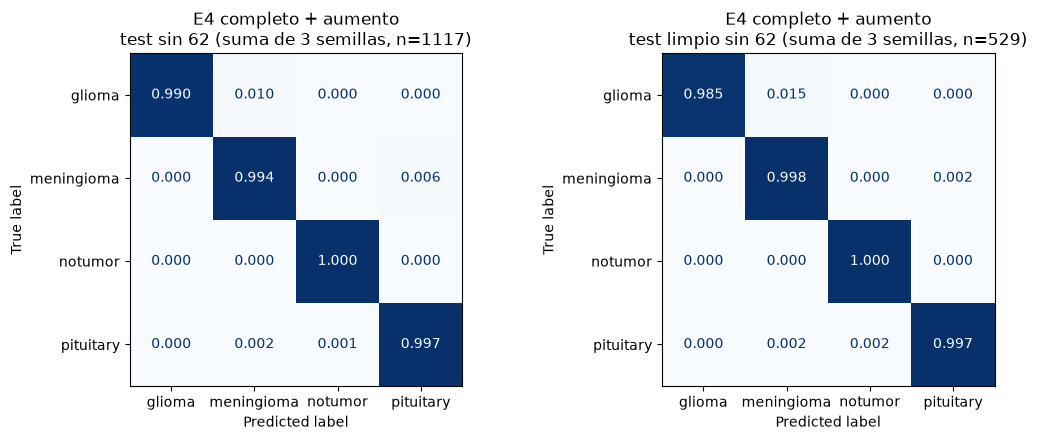

=== sin 62, semilla 0
              precision    recall  f1-score   support

      glioma      1.000     0.987     0.994       314
  meningioma      0.983     0.993     0.988       292
     notumor      0.991     1.000     0.996       113
   pituitary      0.995     0.995     0.995       398

    accuracy                          0.993      1117
   macro avg      0.992     0.994     0.993      1117
weighted avg      0.993     0.993     0.993      1117

=== limpio sin 62, semilla 0
              precision    recall  f1-score   support

      glioma      1.000     0.980     0.990       151
  meningioma      0.975     1.000     0.988       158
     notumor      0.964     1.000     0.982        27
   pituitary      1.000     0.990     0.995       193

    accuracy                          0.991       529
   macro avg      0.985     0.992     0.989       529
weighted avg      0.991     0.991     0.991       529



In [8]:
nombre = "E4 completo + aumento"
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, sub in zip(axes, ("sin 62", "limpio sin 62")):
    m = subconjuntos[sub]
    cm = sum(confusion_matrix(y_test[m], yp[m], labels=range(4)) for yp in preds[nombre])
    ConfusionMatrixDisplay(cm / cm.sum(axis=1, keepdims=True), display_labels=clases).plot(
        ax=ax, values_format=".3f", cmap="Blues", colorbar=False)
    ax.set_title(f"{nombre}\ntest {sub} (suma de 3 semillas, n={m.sum()})")
plt.tight_layout(); plt.show()

for sub in ("sin 62", "limpio sin 62"):
    m = subconjuntos[sub]
    print(f"=== {sub}, semilla 0")
    print(classification_report(y_test[m], preds[nombre][0][m], target_names=clases, digits=3))

## Notas para interpretar

- El test limpio sin los 62 solo tiene 27 imágenes de *notumor*: unos pocos errores en esa clase mueven mucho el F1 macro. Conviene mirar también el acierto y el informe por clase.
- Si al quitar los 62 la caída completo → limpio casi desaparece, se confirma que las casi-copias no eran las que inflaban el test completo.
- Que el resultado mejore al quitar las imágenes difíciles es lo esperable; lo informativo es **cuánto** se acerca a val y si la ordenación de los modelos cambia.